# Pre-entrega 3 – Clasificación supervisada de textos con TF-IDF

**Proyecto: Clasificación de noticias AG News**

## 1. Preprocesamiento del corpus (retomado de la Pre-entrega 2)

En esta primera parte se recupera el trabajo realizado en la Pre-entrega 2, correspondiente a la exploración, limpieza y preprocesamiento del conjunto de datos AG News.

Se utilizan los conjuntos de entrenamiento y prueba previamente cargados, junto con las funciones de normalización, limpieza, tokenización y lematización desarrolladas anteriormente. Estos procedimientos permiten obtener los textos procesados que se utilizarán como entrada para el modelo de clasificación supervisada.

In [59]:
# ============================================
# 1. CARGA DE DATOS
# ============================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Cargar los conjuntos de entrenamiento y prueba
train_df = pd.read_csv("data/ag_news_train.csv")
test_df = pd.read_csv("data/ag_news_test.csv")

print("Datasets cargados correctamente.")

Datasets cargados correctamente.


In [2]:
# ============================================
# 2. EXPLORACIÓN INICIAL DE LOS DATOS
# ============================================

# Dimensiones de los datasets
print("Dimensiones del conjunto de entrenamiento:", train_df.shape)
print("Dimensiones del conjunto de prueba:", test_df.shape)

# Columnas disponibles
print("\nColumnas del dataset:")
print(train_df.columns.tolist())

# Primeras observaciones
print("\nPrimeras observaciones del conjunto de entrenamiento:")
display(train_df.head())

# Verificación de valores nulos
print("\nValores nulos en train:")
display(train_df.isnull().sum())

print("\nValores nulos en test:")
display(test_df.isnull().sum())

Dimensiones del conjunto de entrenamiento: (8000, 2)
Dimensiones del conjunto de prueba: (2000, 2)

Columnas del dataset:
['text', 'label']

Primeras observaciones del conjunto de entrenamiento:


,text,label
0,"Red Hat Appoints New CFO. September 2, 2004 --...",Sci_Tech
1,"Sprint, SBC In Hotspot Roaming Deal. Sprint an...",Sci_Tech
2,Radio Outage Grounds West Coast Flights. Airpo...,Business
3,Hollywood lawsuits to strike Net pirates. Holl...,Sci_Tech
4,Custis Takes Control. Family and Tony Robbins ...,Sports



Valores nulos en train:


,0
text,0
label,0



Valores nulos en test:


,0
text,0
label,0


Cantidad de noticias por categoría:


,count
label,
Sci_Tech,2000
Business,2000
Sports,2000
World,2000



Porcentaje de noticias por categoría:


,proportion
label,
Sci_Tech,25.0
Business,25.0
Sports,25.0
World,25.0


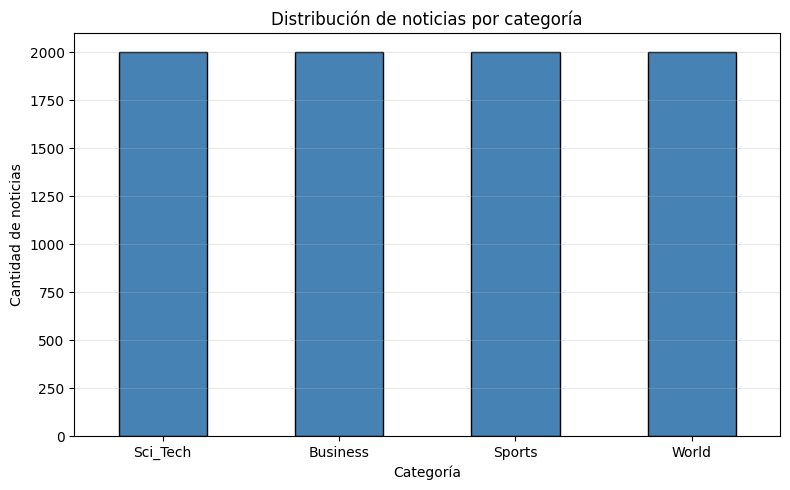

In [3]:
# ============================================
# 3. DISTRIBUCIÓN DE CLASES
# ============================================

# Contar noticias por categoría
distribucion_clases = train_df["label"].value_counts()

print("Cantidad de noticias por categoría:")
display(distribucion_clases)

# Calcular porcentajes
porcentaje_clases = train_df["label"].value_counts(normalize=True) * 100

print("\nPorcentaje de noticias por categoría:")
display(porcentaje_clases.round(2))

# Generar gráfico de barras
plt.figure(figsize=(8, 5))

distribucion_clases.plot(
    kind="bar",
    color="steelblue",
    edgecolor="black"
)

plt.title("Distribución de noticias por categoría")
plt.xlabel("Categoría")
plt.ylabel("Cantidad de noticias")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [4]:
# ============================================
# 4. CONFIGURACIÓN DEL ENTORNO NLP
# ============================================

# Instalar spaCy
!pip install spacy

# Descargar el modelo de inglés
!python -m spacy download en_core_web_sm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 24.6 MB/s  0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [5]:
# Cargar el modelo de inglés de spaCy
import spacy

nlp = spacy.load("en_core_web_sm")

print("Modelo de spaCy cargado correctamente.")

Modelo de spaCy cargado correctamente.


In [6]:
# ============================================
# 5. PIPELINE DE PREPROCESAMIENTO DE TEXTO
# ============================================

import re
import html

def preprocess_text(text, remove_stopwords=True):

    # 1. NORMALIZACIÓN
    text = text.lower()

    # 2. LIMPIEZA DE ENTIDADES HTML
    text = html.unescape(text)

    # Recuperar apóstrofes codificados en el dataset
    text = re.sub(r'#39;', "'", text)

    # Corregir espacios antes de los apóstrofes
    text = re.sub(r"\s+'", "'", text)

    # Eliminar residuos de entidades de comillas
    text = re.sub(r'\bquot(?:;|\b)', ' ', text)

    # 3. NORMALIZACIÓN DE ABREVIATURAS

    # Preservar el nombre propio U.S. Open
    text = re.sub(r'\bu\.s\.\s*open\b', 'usopen', text)

    # Reemplazar otras apariciones de U.S. por United States
    text = re.sub(r'\bu\.s\.(?![a-z])', 'united states', text)

    # 4. LIMPIEZA CON EXPRESIONES REGULARES

    # Eliminar URLs
    text = re.sub(r'https?://\S+|www\.\S+', ' ', text)

    # Eliminar dominios web
    text = re.sub(r'\b(?:[a-z0-9-]+\.)+[a-z]{2,}\b', ' ', text)

    # Eliminar metadatos financieros de Reuters
    text = re.sub(
        r'\bquote\s*,?\s*profile\s*,?\s*research\b',
        ' ',
        text
    )

    # Eliminar etiquetas HTML
    text = re.sub(r'<[^>]*>', ' ', text)

    # Conservar letras, espacios y apóstrofes
    text = re.sub(r"[^a-z\s']", ' ', text)

    # Eliminar espacios repetidos
    text = re.sub(r'\s+', ' ', text).strip()

    # 5. LEMATIZACIÓN CON SPACY
    doc = nlp(text)

    tokens = []

    for token in doc:

      # Ignorar puntuación y espacios
      if token.is_punct or token.is_space:
        continue

      # Eliminar el posesivo 's
      if token.text == "'s":
        continue

      # Obtener el lema del token
      lema = token.lemma_.lower()

      # Eliminar stop-words antes y después de la lematización
      if remove_stopwords and (
          token.is_stop or nlp.vocab[lema].is_stop
      ):
        continue

      tokens.append(lema)

    return ' '.join(tokens)

In [7]:
# ============================================
# 6. PRUEBA DEL PIPELINE CORREGIDO
# ============================================

textos_prueba = [
    "European Union #39;s landmark decisions",
    "China #39;s second manned space mission",
    "He hadn #39;t done this before",
    "A quot;status check quot;",
    "U.S. telecoms firm and U.S. Open",
    "They told us the news"
]

for texto in textos_prueba:

    print("\nORIGINAL:")
    print(texto)

    print("LEMATIZADO:")
    print(preprocess_text(texto, remove_stopwords=False))

    print("SIN STOP-WORDS:")
    print(preprocess_text(texto, remove_stopwords=True))


ORIGINAL:
European Union #39;s landmark decisions
LEMATIZADO:
european union landmark decision
SIN STOP-WORDS:
european union landmark decision

ORIGINAL:
China #39;s second manned space mission
LEMATIZADO:
china second manned space mission
SIN STOP-WORDS:
china second manned space mission

ORIGINAL:
He hadn #39;t done this before
LEMATIZADO:
he have not do this before
SIN STOP-WORDS:


ORIGINAL:
A quot;status check quot;
LEMATIZADO:
a status check
SIN STOP-WORDS:
status check

ORIGINAL:
U.S. telecoms firm and U.S. Open
LEMATIZADO:
united states telecom firm and usopen
SIN STOP-WORDS:
united states telecom firm usopen

ORIGINAL:
They told us the news
LEMATIZADO:
they tell we the news
SIN STOP-WORDS:
tell news


In [8]:
# ============================================
# 7. APLICACIÓN DEL PIPELINE AL CORPUS
# ============================================

# Texto lematizado conservando stop-words
train_df["text_lemmatized"] = train_df["text"].apply(
    lambda text: preprocess_text(text, remove_stopwords=False)
)

# Texto lematizado sin stop-words
train_df["text_processed"] = train_df["text"].apply(
    lambda text: preprocess_text(text, remove_stopwords=True)
)

# Verificar resultados
print("Noticias procesadas:", len(train_df))

print(
    "Textos vacíos:",
    (train_df["text_processed"].str.strip() == "").sum()
)

print("\nEjemplo de comparación:")
display(
    train_df[
        ["text", "text_lemmatized", "text_processed"]
    ].head(3)
)

Noticias procesadas: 8000
Textos vacíos: 0

Ejemplo de comparación:


,text,text_lemmatized,text_processed
0,"Red Hat Appoints New CFO. September 2, 2004 --...",red hat appoint new cfo september web host ind...,red hat appoint new cfo september web host ind...
1,"Sprint, SBC In Hotspot Roaming Deal. Sprint an...",sprint sbc in hotspot roam deal sprint and sbc...,sprint sbc hotspot roam deal sprint sbc commun...
2,Radio Outage Grounds West Coast Flights. Airpo...,radio outage ground west coast flights airport...,radio outage ground west coast flights airport...


In [9]:
# ============================================
# 8. VALIDACIÓN DEL PREPROCESAMIENTO
# ============================================

# Buscar metadatos de Reuters en el texto original
coincidencias_originales = train_df[
    train_df["text"].str.contains(
        r"Quote, Profile, Research",
        case=False,
        na=False
    )
]

# Buscar los mismos metadatos en el texto procesado
coincidencias_procesadas = train_df[
    train_df["text_processed"].str.contains(
        r"quote profile research",
        case=False,
        na=False
    )
]

print(
    "Coincidencias en textos originales:",
    len(coincidencias_originales)
)

print(
    "Coincidencias en textos procesados:",
    len(coincidencias_procesadas)
)

# Comparar un ejemplo
if not coincidencias_originales.empty:

    ejemplo = coincidencias_originales.iloc[0]

    print("\nTEXTO ORIGINAL:")
    print(ejemplo["text"])

    print("\nTEXTO PROCESADO:")
    print(ejemplo["text_processed"])

Coincidencias en textos originales: 65
Coincidencias en textos procesados: 0

TEXTO ORIGINAL:
UPDATE 1-Warburg Pincus to buy 2.75 of Kotak Mahindra Bank. The board of India #39;s Kotak Mahindra Bank Ltd. (KTKM.BO: Quote, Profile, Research) has approved an issue of shares representing a 2.75 percent stake to Warburg Pincus International LLC.

TEXTO PROCESADO:
update warburg pincus buy kotak mahindra bank board india kotak mahindra bank ltd approve issue share represent percent stake warburg pincus international llc


In [10]:
# ============================================
# 9. ANÁLISIS DE LONGITUD DE LOS DOCUMENTOS
# ============================================

# Calcular la cantidad de tokens por noticia
train_df["token_count"] = train_df["text_processed"].apply(
    lambda text: len(text.split())
)

# Estadísticas descriptivas
print("Estadísticas de longitud de los documentos:")
display(train_df["token_count"].describe())

# Calcular el percentil 95
percentil_95 = train_df["token_count"].quantile(0.95)

print("\nPercentil 95:", percentil_95)

Estadísticas de longitud de los documentos:


,token_count
count,8000.000000
mean,23.112500
std,6.046397
min,6.000000
25%,19.000000
50%,23.000000
75%,27.000000
max,71.000000



Percentil 95: 33.0


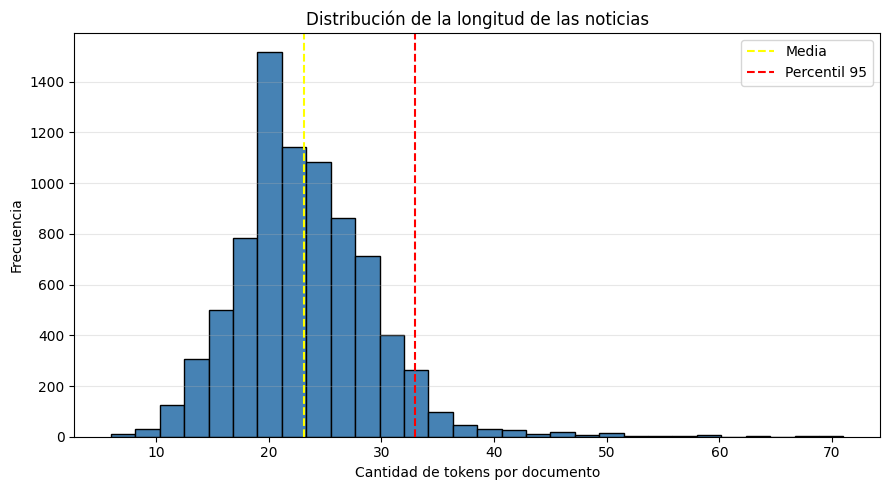

In [11]:
# ============================================
# 10. DISTRIBUCIÓN DE LA LONGITUD DE LOS DOCUMENTOS
# ============================================

plt.figure(figsize=(9, 5))

plt.hist(
    train_df["token_count"],
    bins=30,
    color="steelblue",
    edgecolor="black"
)

# Marcar la media
plt.axvline(
    train_df["token_count"].mean(),
    color="yellow",
    linestyle="--",
    label="Media"
)

# Marcar el percentil 95
plt.axvline(
    percentil_95,
    color="red",
    linestyle="--",
    label="Percentil 95"
)

plt.title("Distribución de la longitud de las noticias")
plt.xlabel("Cantidad de tokens por documento")
plt.ylabel("Frecuencia")
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

La distribución de la longitud de los documentos presenta un único máximo de frecuencia, ubicado aproximadamente entre 19 y 21 tokens, y una asimetría positiva. La mayor concentración de noticias se encuentra entre 18 y 30 tokens. La longitud media es de 23,12 tokens, mientras que la mediana es de 23, lo que indica que ambas medidas de tendencia central son similares. Se observa una cola hacia la derecha, correspondiente a un número reducido de noticias más extensas. El percentil 95 se ubica en 33 tokens, lo que indica que aproximadamente el 95 % de los documentos tiene una longitud igual o inferior a ese valor.

In [12]:
# ============================================
# 11. ANÁLISIS DE N-GRAMAS
# ============================================

from sklearn.feature_extraction.text import CountVectorizer

# Función para obtener los n-gramas más frecuentes
def obtener_top_ngrams(textos, ngram_range, top_n=20):

    vectorizer = CountVectorizer(ngram_range=ngram_range)

    matriz = vectorizer.fit_transform(textos)

    frecuencias = matriz.sum(axis=0).A1

    ngramas = vectorizer.get_feature_names_out()

    resultados = pd.DataFrame({
        "N-grama": ngramas,
        "Frecuencia": frecuencias
    })

    return resultados.sort_values(
        by="Frecuencia",
        ascending=False
    ).head(top_n).reset_index(drop=True)


# Obtener los 20 bigramas más frecuentes
top_20_bigramas = obtener_top_ngrams(
    train_df["text_processed"],
    ngram_range=(2, 2),
    top_n=20
)

# Obtener los 20 trigramas más frecuentes
top_20_trigramas = obtener_top_ngrams(
    train_df["text_processed"],
    ngram_range=(3, 3),
    top_n=20
)

print("TOP 20 BIGRAMAS:")
display(top_20_bigramas)

print("\nTOP 20 TRIGRAMAS:")
display(top_20_trigramas)

TOP 20 BIGRAMAS:


,N-grama,Frecuencia
0,united states,652
1,ap ap,529
2,new york,419
3,oil price,197
4,york reuters,157
5,prime minister,139
6,afp afp,134
7,reuters reuters,114
8,red sox,98
9,los angeles,96



TOP 20 TRIGRAMAS:


,N-grama,Frecuencia
0,new york reuters,157
1,reuters united states,86
2,york reuters united,42
3,united states stock,37
4,boston red sox,37
5,high oil price,27
6,canadian press canadian,26
7,prime minister ariel,26
8,press canadian press,26
9,minister ariel sharon,25


El análisis de los n-gramas permitió identificar patrones frecuentes asociados tanto al contenido temático de las noticias como a la estructura del corpus.

Entre los bigramas se destacan referencias geográficas, como *united states* y *new york*; términos relacionados con la economía, como *oil price* y *wall street*; y expresiones vinculadas con la política y los deportes, como *prime minister*, *president bush* y *red sox*.

En los trigramas aparecen nombres propios y entidades, referencias a figuras políticas y expresiones relacionadas con la economía, los deportes y la ciencia, como *high oil price*, *president vladimir putin* e *international space station*.

También se observa la repetición de siglas y nombres de agencias informativas, como AP, AFP y Reuters, que responde al formato de los registros originales.

Cabe señalar que el análisis se realizó sobre textos sin stop-words. Por lo tanto, los n-gramas representan secuencias de palabras de contenido y no necesariamente expresiones consecutivas del texto original.

In [13]:
# ============================================
# 12. INSPECCIÓN DE POSIBLES RESIDUOS EN LOS N-GRAMAS
# ============================================

# Inspeccionar expresiones frecuentes para identificar
# posibles residuos del formato original de las noticias.

# Expresiones que queremos investigar
expresiones = [
    "ap ap",
    "afp afp",
    "reuter reuter",
    "reuters reuters",
    "new york reuters"
]

for expresion in expresiones:

    print(f"\n{'=' * 60}")
    print(f"EXPRESIÓN: {expresion}")
    print(f"{'=' * 60}")

    coincidencias = train_df[
        train_df["text_processed"].str.contains(
            expresion,
            regex=False,
            na=False
        )
    ]

    print("Cantidad de noticias:", len(coincidencias))

    # Mostrar hasta tres ejemplos
    for _, fila in coincidencias.head(3).iterrows():

        print("\nTEXTO ORIGINAL:")
        print(fila["text"])

        print("\nTEXTO PROCESADO:")
        print(fila["text_processed"])


EXPRESIÓN: ap ap
Cantidad de noticias: 530

TEXTO ORIGINAL:
U.N. to Debate Anti-Cloning Treaty (AP). AP - The highly contentious issue of cloning is back on the U.N. agenda, with support among member states for a treaty banning human cloning but divisions over the use of human embryos for medical research.

TEXTO PROCESADO:
u n debate anti cloning treaty ap ap highly contentious issue cloning u n agenda support member state treaty ban human cloning division use human embryo medical research

TEXTO ORIGINAL:
Microsoft CEO: Hackers Getting Smarter (AP). AP - Microsoft Corp.'s chief executive believes it's naive to suggest the software giant can eliminate all security vulnerabilities in its various products even though engineers are trying hard to do so.

TEXTO PROCESADO:
microsoft ceo hacker smart ap ap microsoft corp chief executive believe naive suggest software giant eliminate security vulnerability product engineer try hard

TEXTO ORIGINAL:
Aid Flight Delayed After Plane Hits Cow (A

La inspección de los textos originales permitió identificar que algunas de las secuencias frecuentes detectadas en el análisis de n-gramas corresponden a elementos estructurales del formato periodístico. En los ejemplos examinados, las repeticiones de AP, AFP y Reuters se relacionan con la inclusión del nombre de la agencia informativa en distintas partes del registro de la noticia. Asimismo, expresiones como *new york reuters* corresponden a encabezados que combinan una referencia geográfica con la identificación de la fuente de información.

Estos elementos no representan necesariamente contenido temático, por lo que deben tenerse en cuenta al interpretar las frecuencias obtenidas. Sin embargo, se decidió conservarlos durante esta etapa del preprocesamiento, dado que forman parte de los textos originales del corpus.

In [14]:
# ============================================
# 13. FRECUENCIA DE PALABRAS Y STOP-WORDS
# ============================================

from collections import Counter

# Separar los textos en palabras y contar sus frecuencias
todas_las_palabras = " ".join(
    train_df["text_lemmatized"]
).split()

frecuencias_palabras = Counter(todas_las_palabras)

# Obtener las 50 palabras más frecuentes
top_50_palabras = pd.DataFrame(
    frecuencias_palabras.most_common(50),
    columns=["Palabra", "Frecuencia"]
)

print("TOP 50 PALABRAS MÁS FRECUENTES:")
display(top_50_palabras)

TOP 50 PALABRAS MÁS FRECUENTES:


,Palabra,Frecuencia
0,the,13686
1,to,7961
2,a,7227
3,of,6575
4,in,6362
5,be,4761
6,and,4636
7,on,3772
8,for,3408
9,have,2455


El análisis de las 50 palabras más frecuentes, realizado sobre los textos lematizados sin eliminar las stop-words, muestra un predominio de términos funcionales del idioma inglés. Entre las palabras más frecuentes se encuentran artículos, preposiciones, conjunciones y formas verbales, como *the*, *to*, *of*, *in*, *and* y *be*.

También aparecen términos asociados al contenido de las noticias, como *new*, *year*, *company*, *world*, *game* y *oil*. Esta distribución permite observar la contribución de las palabras funcionales a la frecuencia global del vocabulario y motiva su identificación para evaluar su tratamiento durante el preprocesamiento.

In [15]:
# ============================================
# 14. IDENTIFICACIÓN DE STOP-WORDS
# ============================================

# Identificar si cada palabra pertenece a las stop-words de spaCy
top_50_palabras["Es_stopword"] = top_50_palabras["Palabra"].apply(
    lambda palabra: nlp.vocab[palabra].is_stop
)

# Mostrar la tabla completa
print("TOP 50 PALABRAS Y CLASIFICACIÓN COMO STOP-WORDS:")
display(top_50_palabras)

# Contar cuántas son stop-words
cantidad_stopwords = top_50_palabras["Es_stopword"].sum()

cantidad_no_stopwords = len(top_50_palabras) - cantidad_stopwords

print("\nResumen:")
print("Total de palabras analizadas:", len(top_50_palabras))
print("Stop-words:", cantidad_stopwords)
print("Palabras que no son stop-words:", cantidad_no_stopwords)

print(
    "Porcentaje de stop-words:",
    round(cantidad_stopwords / len(top_50_palabras) * 100, 2),
    "%"
)

TOP 50 PALABRAS Y CLASIFICACIÓN COMO STOP-WORDS:


,Palabra,Frecuencia,Es_stopword
0,the,13686,True
1,to,7961,True
2,a,7227,True
3,of,6575,True
4,in,6362,True
5,be,4761,True
6,and,4636,True
7,on,3772,True
8,for,3408,True
9,have,2455,True



Resumen:
Total de palabras analizadas: 50
Stop-words: 37
Palabras que no son stop-words: 13
Porcentaje de stop-words: 74.0 %


Se analizaron las 50 palabras más frecuentes del corpus y se verificó su clasificación como stop-words mediante spaCy. Se identificaron 37 palabras pertenecientes a esta categoría, lo que representa el 74 % del total, mientras que las 13 restantes (26 %) no fueron clasificadas como stop-words.

Entre las primeras predominan artículos, preposiciones, conjunciones y formas verbales frecuentes del inglés. En cambio, entre las palabras que no son stop-words se encuentran términos con mayor contenido semántico, como *company*, *world*, *win*, *game*, *report* y *oil*.

Estos resultados muestran que una proporción importante de las palabras más frecuentes corresponde a elementos funcionales del lenguaje. Su eliminación durante el preprocesamiento permite reducir la presencia de estos términos y destacar el vocabulario más relacionado con el contenido temático de las noticias.

In [16]:
# ============================================
# 15. INSPECCIÓN DE POSIBLES RESIDUOS
# ============================================

palabras_revision = ["s", "quot", "u"]

for palabra in palabras_revision:

    print(f"\n{'=' * 60}")
    print(f"PALABRA: {palabra}")
    print(f"{'=' * 60}")

    # Buscar la palabra como token independiente
    coincidencias = train_df[
        train_df["text_lemmatized"].str.contains(
            rf"\b{palabra}\b",
            regex=True,
            na=False
        )
    ]

    print("Cantidad de noticias:", len(coincidencias))

    # Mostrar hasta cinco ejemplos
    for _, fila in coincidencias.head(5).iterrows():

        print("\nTEXTO ORIGINAL:")
        print(fila["text"])

        print("\nTEXTO LEMATIZADO:")
        print(fila["text_lemmatized"])

        print("\nTEXTO SIN STOP-WORDS:")
        print(fila["text_processed"])


PALABRA: s
Cantidad de noticias: 81

TEXTO ORIGINAL:
Philip Morris lab discovered passive smoking risk in 1982: Lancet. PARIS (AFP) - A lab owned by US tobacco giant Philip Morris uncovered evidence in the early 1980s about potential risks from passive smoking but its findings were never made public, a study charges.

TEXTO LEMATIZADO:
philip morris lab discover passive smoking risk in lancet paris afp a lab own by we tobacco giant philip morris uncover evidence in the early s about potential risk from passive smoking but its finding be never make public a study charge

TEXTO SIN STOP-WORDS:
philip morris lab discover passive smoking risk lancet paris afp lab tobacco giant philip morris uncover evidence early s potential risk passive smoking finding public study charge

TEXTO ORIGINAL:
U.S.C., Miami Top B.C.S. Standings, Not Oklahoma. Southern California took the top spot Monday in the season's first Bowl Championship Series standings.

TEXTO LEMATIZADO:
u s c miami top b c s standing

Se realizó una inspección adicional de posibles residuos en los textos lematizados mediante la búsqueda de tokens aislados como *s*, *quot* y *u*. No se encontraron coincidencias para *quot*, lo que resulta consistente con las reglas de limpieza de entidades HTML incorporadas al preprocesamiento.

En cambio, se identificaron 81 noticias con el token *s* y 60 con *u*. La revisión de los ejemplos permitió observar que estas apariciones se relacionan principalmente con la separación de abreviaturas durante la eliminación de signos de puntuación, como *U.S.C.*, *U.N.* y *U.S.*. También se identificaron otros usos, como la terminación de expresiones temporales (por ejemplo, *1980s*) y fragmentos de expresiones como *S&P*.

Estos resultados muestran que, aunque el preprocesamiento elimina gran parte del ruido del corpus, algunos tokens aislados persisten como consecuencia de la estructura y el formato de los textos originales. Se decidió conservar el pipeline sin incorporar reglas adicionales para estos casos, dado que su eliminación indiscriminada podría afectar información válida.

In [17]:
# ============================================
# 16. VERIFICACIÓN DE ENTIDADES Y ABREVIATURAS
# ============================================

# Buscar ejemplos de cada patrón en los textos originales

patrones_revision = {
    "Apóstrofes codificados (#39)": r"#39;",
    "Entidades quot": r"quot",
    "Abreviatura U.S.": r"\bU\.S\."
}

for nombre, patron in patrones_revision.items():

    coincidencias = train_df[
        train_df["text"].str.contains(
            patron,
            case=False,
            regex=True,
            na=False
        )
    ]

    print(f"\n{nombre}")
    print("Cantidad de noticias:", len(coincidencias))

    for texto in coincidencias["text"].head(3):
        print("-", texto[:300])


Apóstrofes codificados (#39)
Cantidad de noticias: 2008
- WorldCom, Microsoft cases before EU court. Two of the European Union #39;s landmark antitrust decisions against US companies are in court this week as WorldCom Inc. seeks a moral victory and Microsoft Corp.
- Homer-happy Mariners end skid. A four-pitch sequence in the fifth inning Friday night produced something the Mariners hadn #39;t done in nearly eight years. Miguel Olivo hit a home run to left-center field.
- Chinese astronauts to wear lighter outfits. China has developed a light and removable spacesuit for its astronauts set to embark on China #39;s second manned space mission scheduled for next September.

Entidades quot
Cantidad de noticias: 536
- Driver #39;s license gets new high-tech features. Minnesota will soon begin issuing new driver #39;s licenses that contain high-tech features to curb counterfeiting, as well as a quot;status check quot; that will show a driver #39;s immigration status.
- UPDATE 1-Warburg Pincu

La inspección de los textos originales permitió identificar distintas representaciones de caracteres especiales y abreviaturas propias del formato del corpus. Se encontraron apóstrofes codificados como `#39;` en 2.008 noticias, entidades de comillas representadas por `quot` en 536 noticias y abreviaturas `U.S.` en 397 noticias.

Estos resultados permitieron reconocer elementos que requerían un tratamiento específico dentro del pipeline de preprocesamiento. Se incorporaron reglas para recuperar los apóstrofes, eliminar las entidades de comillas y normalizar las abreviaturas, contemplando la excepción del nombre propio *U.S. Open*, que se conserva como `usopen` para evitar una transformación incorrecta.

La inspección posterior de los textos procesados permitió comprobar el tratamiento de estos elementos y detectar algunos tokens residuales, cuya interpretación se desarrolló en el análisis anterior.

In [18]:

# ============================================
# 17. TOP 50 PALABRAS MÁS FRECUENTES SIN STOP-WORDS
# ============================================

from collections import Counter

# Unir todos los textos procesados y separar en palabras
todas_las_palabras = " ".join(
    train_df["text_processed"]
).split()

# Contabilizar la frecuencia de cada palabra
frecuencias = Counter(todas_las_palabras)

# Obtener las 50 palabras más frecuentes
top_50_sin_stopwords = pd.DataFrame(
    frecuencias.most_common(50),
    columns=["Palabra", "Frecuencia"]
)

# Mostrar resultados
print("TOP 50 PALABRAS MÁS FRECUENTES SIN STOP-WORDS:")
display(top_50_sin_stopwords)


TOP 50 PALABRAS MÁS FRECUENTES SIN STOP-WORDS:


,Palabra,Frecuencia
0,new,1430
1,ap,1117
2,year,969
3,united,818
4,reuters,800
5,states,654
6,company,650
7,world,608
8,win,577
9,game,552


El análisis de las 50 palabras más frecuentes luego de eliminar las stop-words muestra una mayor presencia de términos asociados al contenido temático de las noticias. Se destacan referencias geográficas y políticas, como *united*, *states*, *iraq* y *president*; términos vinculados con la economía, como *company*, *oil*, *price*, *stock* y *market*; y palabras relacionadas con los deportes, como *win*, *game*, *season* y *team*. También se identifican referencias temporales frecuentes, como *year*, *monday* y *week*.

Persisten términos correspondientes a agencias informativas, como AP y Reuters, cuya presencia se relaciona con la estructura original del corpus. En comparación con la distribución obtenida antes de eliminar las stop-words, se observa una menor presencia de palabras funcionales y una mayor representación del vocabulario relacionado con los contenidos de las noticias.

## 2. Clasificación supervisada de noticias mediante TF-IDF

In [36]:
# ============================================
# 18. PREPROCESAMIENTO DEL CONJUNTO DE PRUEBA
# ============================================

# Aplicar el mismo pipeline de preprocesamiento utilizado en train_df
test_df["text_processed"] = test_df["text"].apply(
    lambda text: preprocess_text(text, remove_stopwords=True)
)

# Verificar los resultados
display(test_df[["text_processed", "label"]].head())

,text_processed,label
0,bskyb profit rise strong subscriber growth afp...,World
1,bell rouse co share jump rse n jump bell gener...,Business
2,minutemen ko'd duke harrisonburg va oppose run...,Sports
3,hacker spoofer malware oh ie exploit code boos...,Sci_Tech
4,ravens ogden miss week baltimore md sports net...,Sports


In [37]:
# ============================================
# 19. VERIFICACIÓN DE LOS CONJUNTOS DE DATOS
# ============================================

# Verificar dimensiones y columnas disponibles
print("Dimensiones de train_df:", train_df.shape)
print("Dimensiones de test_df:", test_df.shape)

print("\nColumnas de train_df:", train_df.columns.tolist())
print("Columnas de test_df:", test_df.columns.tolist())

# Comparar ejemplos de textos procesados y sus etiquetas
display(train_df[["text_processed", "label"]].head(3))
display(test_df[["text_processed", "label"]].head(3))

Dimensiones de train_df: (8000, 5)
Dimensiones de test_df: (2000, 3)

Columnas de train_df: ['text', 'label', 'text_lemmatized', 'text_processed', 'token_count']
Columnas de test_df: ['text', 'label', 'text_processed']


,text_processed,label
0,red hat appoint new cfo september web host ind...,Sci_Tech
1,sprint sbc hotspot roam deal sprint sbc commun...,Sci_Tech
2,radio outage ground west coast flights airport...,Business


,text_processed,label
0,bskyb profit rise strong subscriber growth afp...,World
1,bell rouse co share jump rse n jump bell gener...,Business
2,minutemen ko'd duke harrisonburg va oppose run...,Sports


### 2.1. Vectorización de los textos mediante TF-IDF

Para utilizar los textos en un modelo de clasificación supervisada, es necesario transformarlos en una representación numérica. Para ello, se emplea la técnica TF-IDF (*Term Frequency–Inverse Document Frequency*), que asigna un peso a cada término en función de su frecuencia en un documento y de su distribución en el conjunto de textos.

Se utiliza `TfidfVectorizer` de Scikit-learn, que permite construir una matriz de características a partir de los textos procesados. En esta primera configuración se consideran únicamente unigramas y se limita el vocabulario a 5.000 características.

Para evitar la filtración de información (*data leakage*), el vectorizador se ajusta exclusivamente con los datos de entrenamiento (`fit_transform`) y luego se aplica al conjunto de prueba mediante `transform`, utilizando el vocabulario y los pesos aprendidos durante el entrenamiento.

In [38]:
# ============================================
# 20. VECTORIZACIÓN TF-IDF - CONFIGURACIÓN 1
# ============================================

from sklearn.feature_extraction.text import TfidfVectorizer

# Inicializar el vectorizador: 5000 características y unigramas
tfidf_vectorizer = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 1)
)

# Ajustar el vectorizador y transformar los datos de entrenamiento
X_train_tfidf = tfidf_vectorizer.fit_transform(train_df["text_processed"])

# Transformar los datos de prueba con el vectorizador ya ajustado
X_test_tfidf = tfidf_vectorizer.transform(test_df["text_processed"])

# Verificar las dimensiones de las matrices resultantes
print("Dimensiones de X_train_tfidf:", X_train_tfidf.shape)
print("Dimensiones de X_test_tfidf:", X_test_tfidf.shape)

Dimensiones de X_train_tfidf: (8000, 5000)
Dimensiones de X_test_tfidf: (2000, 5000)


### 2.2. Entrenamiento del modelo de clasificación

Se utiliza `LinearSVC` (*Linear Support Vector Classifier*) para realizar la clasificación supervisada de las noticias. Este algoritmo busca establecer fronteras de decisión que permitan distinguir las categorías a partir de las características numéricas obtenidas mediante TF-IDF.

Se seleccionó este clasificador por su adecuación a problemas de clasificación de textos representados mediante matrices dispersas y de alta dimensionalidad.

El modelo se entrena utilizando exclusivamente la matriz TF-IDF del conjunto de entrenamiento y sus etiquetas correspondientes.

In [39]:
# ============================================
# 21. ENTRENAMIENTO DEL CLASIFICADOR LINEARSVC
# ============================================

from sklearn.svm import LinearSVC

# Inicializar el clasificador
svm_model = LinearSVC(random_state=42)

# Entrenar el modelo con los datos de entrenamiento vectorizados
svm_model.fit(X_train_tfidf, train_df["label"])

print("Modelo entrenado correctamente.")

Modelo entrenado correctamente.


In [40]:
# ============================================
# 22. PREDICCIÓN SOBRE EL CONJUNTO DE PRUEBA
# ============================================

# Predecir las categorías de las noticias del conjunto de prueba
y_pred = svm_model.predict(X_test_tfidf)

# Comparar las categorías reales con las predichas
resultados = pd.DataFrame({
    "Categoria_real": test_df["label"],
    "Categoria_predicha": y_pred
})

# Visualizar las primeras 10 predicciones
display(resultados.head(10))

,Categoria_real,Categoria_predicha
0,World,Business
1,Business,Business
2,Sports,Sports
3,Sci_Tech,Sci_Tech
4,Sports,Sports
5,Sports,Sports
6,Sci_Tech,Sci_Tech
7,World,Business
8,Business,Business
9,Sports,Sports


In [41]:
# ============================================
# 23. EVALUACIÓN DEL MODELO - CLASSIFICATION REPORT
# ============================================

from sklearn.metrics import classification_report

# Generar el informe de clasificación
reporte = classification_report(
    test_df["label"],
    y_pred,
    digits=4
)

print(reporte)

              precision    recall  f1-score   support

    Business     0.8212    0.8540    0.8373       500
    Sci_Tech     0.8717    0.8560    0.8638       500
      Sports     0.9396    0.9640    0.9516       500
       World     0.8992    0.8560    0.8770       500

    accuracy                         0.8825      2000
   macro avg     0.8829    0.8825    0.8824      2000
weighted avg     0.8829    0.8825    0.8824      2000



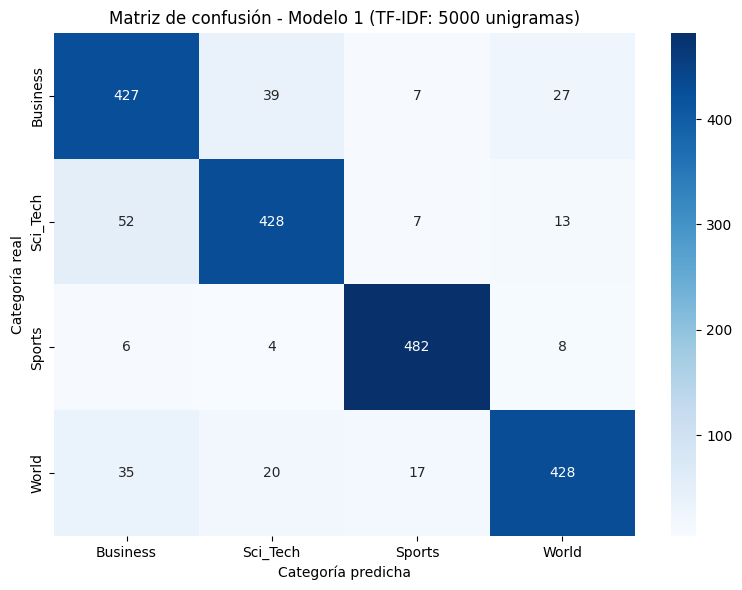

In [42]:
# ============================================
# 24. MATRIZ DE CONFUSIÓN - MODELO 1
# ============================================

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Calcular la matriz de confusión
cm = confusion_matrix(test_df["label"], y_pred)

# Visualizar la matriz
plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=svm_model.classes_,
    yticklabels=svm_model.classes_
)

plt.xlabel("Categoría predicha")
plt.ylabel("Categoría real")
plt.title("Matriz de confusión - Modelo 1 (TF-IDF: 5000 unigramas)")
plt.tight_layout()
plt.show()

La matriz de confusión muestra que el modelo presenta un buen desempeño general, con 1765 noticias correctamente clasificadas sobre un total de 2000 (88,25 % de exactitud). La categoría Sports presenta el mejor resultado, con 482 clasificaciones correctas y un recall del 96,4 %.

Por otro lado, las mayores dificultades se observan en la distinción entre Sci_Tech y Business: 52 noticias de la primera categoría fueron clasificadas como Business, mientras que 14 noticias de Business fueron clasificadas como Sci_Tech. También se observa confusión entre Business y World, especialmente en noticias de Business clasificadas como World (58 casos) y de World clasificadas como Business (35 casos).

Estos resultados sugieren que algunas categorías presentan vocabulario compartido o contextos temáticos similares, lo que dificulta su diferenciación mediante la representación TF-IDF utilizada.

### 2.3. Evaluación de una segunda configuración de TF-IDF

Con el objetivo de evaluar el efecto de incorporar información contextual adicional, se implementa una segunda configuración de TF-IDF que considera tanto unigramas como bigramas (`ngram_range=(1,2)`).

Se mantiene el límite de 5.000 características (`max_features=5000`), de modo que la comparación con la configuración anterior permita analizar específicamente el efecto de incorporar combinaciones de dos palabras en la representación de los textos.

A partir de esta nueva representación, se entrena nuevamente el clasificador LinearSVC y se evalúa su desempeño mediante las métricas de clasificación.

In [43]:
# ============================================
# 25. VECTORIZACIÓN TF-IDF - CONFIGURACIÓN 2
# ============================================

# Inicializar el vectorizador: 5000 características y unigramas + bigramas
tfidf_vectorizer_2 = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2)
)

# Ajustar el vectorizador con los datos de entrenamiento
X_train_tfidf_2 = tfidf_vectorizer_2.fit_transform(train_df["text_processed"])

# Transformar los datos de prueba con el vectorizador ya ajustado
X_test_tfidf_2 = tfidf_vectorizer_2.transform(test_df["text_processed"])

# Verificar las dimensiones de las matrices resultantes
print("Dimensiones de X_train_tfidf_2:", X_train_tfidf_2.shape)
print("Dimensiones de X_test_tfidf_2:", X_test_tfidf_2.shape)

Dimensiones de X_train_tfidf_2: (8000, 5000)
Dimensiones de X_test_tfidf_2: (2000, 5000)


In [44]:
# ============================================
# 26. ENTRENAMIENTO DEL MODELO 2 - LINEARSVC
# ============================================

# Inicializar el segundo clasificador
svm_model_2 = LinearSVC(random_state=42)

# Entrenar el modelo con la nueva representación TF-IDF
svm_model_2.fit(X_train_tfidf_2, train_df["label"])

# Generar predicciones sobre el conjunto de prueba
y_pred_2 = svm_model_2.predict(X_test_tfidf_2)

print("Segundo modelo entrenado y predicciones generadas correctamente.")

Segundo modelo entrenado y predicciones generadas correctamente.


In [45]:
# ============================================
# 27. EVALUACIÓN DEL MODELO 2 - CLASSIFICATION REPORT
# ============================================

from sklearn.metrics import classification_report

# Generar el informe de clasificación
reporte_2 = classification_report(
    test_df["label"],
    y_pred_2,
    digits=4
)

print(reporte_2)

              precision    recall  f1-score   support

    Business     0.8317    0.8700    0.8504       500
    Sci_Tech     0.8725    0.8620    0.8672       500
      Sports     0.9449    0.9600    0.9524       500
       World     0.9032    0.8580    0.8800       500

    accuracy                         0.8875      2000
   macro avg     0.8881    0.8875    0.8875      2000
weighted avg     0.8881    0.8875    0.8875      2000



La incorporación de bigramas mediante `ngram_range=(1,2)` produjo una mejora moderada respecto de la configuración basada exclusivamente en unigramas. El accuracy pasó de 0,8825 a 0,8875, mientras que el F1-score macro aumentó de 0,8824 a 0,8875.

Al analizar las métricas por categoría, se observa una mejora en Business, cuyo F1-score pasó de 0,84 a 0,85, y en Sci_Tech, que pasó de 0,86 a 0,87. En Sports y World, el desempeño se mantuvo prácticamente estable.

Estos resultados sugieren que la incorporación de combinaciones de dos palabras aporta información adicional para la clasificación de noticias, aunque la mejora obtenida es relativamente pequeña.

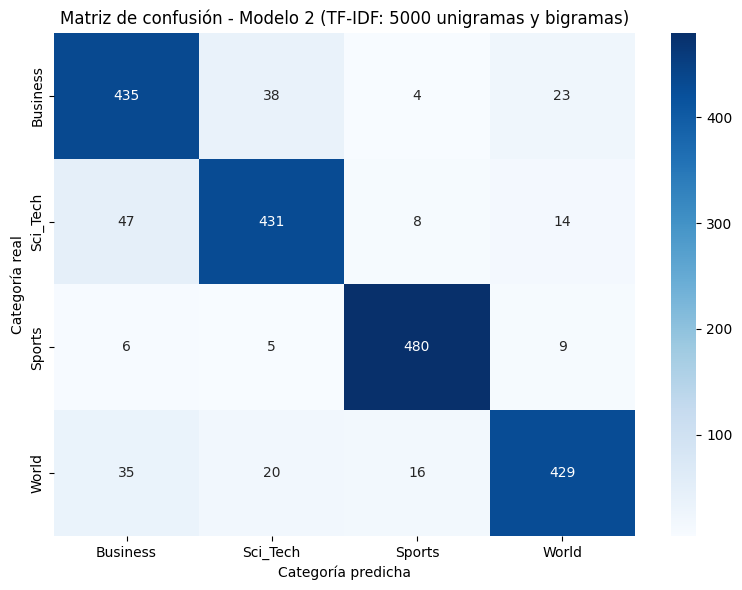

In [46]:
# ============================================
# 28. MATRIZ DE CONFUSIÓN - MODELO 2
# ============================================

from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Calcular la matriz de confusión
cm_2 = confusion_matrix(test_df["label"], y_pred_2)

# Visualizar la matriz
plt.figure(figsize=(8, 6))

sns.heatmap(
    cm_2,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=svm_model_2.classes_,
    yticklabels=svm_model_2.classes_
)

plt.xlabel("Categoría predicha")
plt.ylabel("Categoría real")
plt.title("Matriz de confusión - Modelo 2 (TF-IDF: 5000 unigramas y bigramas)")
plt.tight_layout()
plt.show()

La matriz de confusión muestra que el segundo modelo presenta una mejora moderada respecto de la configuración inicial, con 1775 noticias correctamente clasificadas sobre un total de 2000 (88,75 % de exactitud).

La categoría Sports continúa presentando el mejor desempeño, con 480 clasificaciones correctas y un recall del 96 %. Por otro lado, Business alcanza un recall del 87 %, mientras que Sci_Tech y World presentan valores del 86,2 % y 85,8 %, respectivamente.

Las confusiones más frecuentes siguen observándose entre Business y Sci_Tech, con 38 noticias de Business clasificadas como Sci_Tech y 47 de Sci_Tech clasificadas como Business. También persiste cierta confusión entre Business y World, aunque disminuyeron las noticias de Business clasificadas como World respecto del primer modelo (23 frente a 58).

En conjunto, estos resultados indican que la incorporación de bigramas permitió mejorar ligeramente la clasificación general y reducir algunas confusiones entre categorías, aunque las dificultades para distinguir noticias de temáticas similares persisten.

### 2.4. Evaluación de una tercera configuración de TF-IDF

Para continuar explorando el efecto de los parámetros del vectorizador sobre el desempeño del clasificador, se implementa una tercera configuración de TF-IDF. En esta oportunidad, se mantiene la incorporación de unigramas y bigramas (`ngram_range=(1,2)`), pero se aumenta el número máximo de características de 5.000 a 10.000 (`max_features=10000`).

Esta modificación permite evaluar si la ampliación del vocabulario aporta información adicional para distinguir las categorías de noticias.

Al igual que en las configuraciones anteriores, se utiliza LinearSVC como algoritmo de clasificación y se mantiene el mismo procedimiento de entrenamiento y evaluación.

In [47]:
# ============================================
# 29. VECTORIZACIÓN TF-IDF - CONFIGURACIÓN 3
# ============================================

# Inicializar el vectorizador: 10000 características y unigramas + bigramas
tfidf_vectorizer_3 = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2)
)

# Ajustar el vectorizador con los datos de entrenamiento
X_train_tfidf_3 = tfidf_vectorizer_3.fit_transform(train_df["text_processed"])

# Transformar los datos de prueba con el vectorizador ya ajustado
X_test_tfidf_3 = tfidf_vectorizer_3.transform(test_df["text_processed"])

# Verificar las dimensiones de las matrices resultantes
print("Dimensiones de X_train_tfidf_3:", X_train_tfidf_3.shape)
print("Dimensiones de X_test_tfidf_3:", X_test_tfidf_3.shape)

Dimensiones de X_train_tfidf_3: (8000, 10000)
Dimensiones de X_test_tfidf_3: (2000, 10000)


In [48]:
# ============================================
# 30. ENTRENAMIENTO DEL MODELO 3 - LINEARSVC
# ============================================

# Inicializar el tercer clasificador
svm_model_3 = LinearSVC(random_state=42)

# Entrenar el modelo con la nueva representación TF-IDF
svm_model_3.fit(X_train_tfidf_3, train_df["label"])

# Generar predicciones sobre el conjunto de prueba
y_pred_3 = svm_model_3.predict(X_test_tfidf_3)

print("Tercer modelo entrenado y predicciones generadas correctamente.")

Tercer modelo entrenado y predicciones generadas correctamente.


In [49]:
# ============================================
# 31. EVALUACIÓN DEL MODELO 3 - CLASSIFICATION REPORT
# ============================================

from sklearn.metrics import classification_report

# Generar el informe de clasificación
reporte_3 = classification_report(
    test_df["label"],
    y_pred_3,
    digits=4
)

print(reporte_3)

              precision    recall  f1-score   support

    Business     0.8359    0.8660    0.8507       500
    Sci_Tech     0.8806    0.8700    0.8753       500
      Sports     0.9489    0.9660    0.9574       500
       World     0.9123    0.8740    0.8927       500

    accuracy                         0.8940      2000
   macro avg     0.8944    0.8940    0.8940      2000
weighted avg     0.8944    0.8940    0.8940      2000



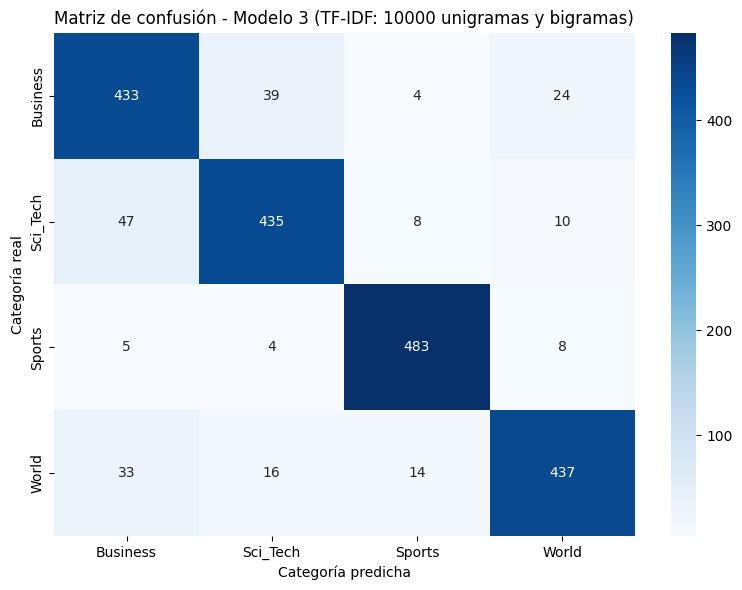

In [50]:
# ============================================
# 32. MATRIZ DE CONFUSIÓN - MODELO 3
# ============================================

from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Calcular la matriz de confusión
cm_3 = confusion_matrix(test_df["label"], y_pred_3)

# Visualizar la matriz
plt.figure(figsize=(8, 6))

sns.heatmap(
    cm_3,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=svm_model_3.classes_,
    yticklabels=svm_model_3.classes_
)

plt.xlabel("Categoría predicha")
plt.ylabel("Categoría real")
plt.title("Matriz de confusión - Modelo 3 (TF-IDF: 10000 unigramas y bigramas)")
plt.tight_layout()
plt.show()

La matriz de confusión muestra que el tercer modelo presenta el mejor desempeño general de las tres configuraciones evaluadas, con 1788 noticias correctamente clasificadas sobre un total de 2000 (89,4 % de exactitud).

La categoría Sports continúa siendo la mejor identificada, con 483 clasificaciones correctas y un recall del 96,6 %. En las restantes categorías, Business alcanza un recall del 86,6 %, Sci_Tech del 87 % y World del 87,4 %.

Las confusiones más frecuentes siguen produciéndose entre Business y Sci_Tech, con 39 noticias de Business clasificadas como Sci_Tech y 47 de Sci_Tech clasificadas como Business. También persiste cierta confusión entre Business y World, aunque se observa una disminución de los errores en esta última relación respecto de las configuraciones anteriores.

En comparación con los modelos previos, la ampliación del vocabulario a 10.000 características permitió mejorar la clasificación general y el reconocimiento de algunas categorías, particularmente Sci_Tech y World. Sin embargo, las dificultades para distinguir noticias de temáticas similares continúan presentes.

In [51]:
# ============================================
# 33. COMPARACIÓN DEL RENDIMIENTO DE LOS MODELOS
# ============================================

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score
)
import pandas as pd

# Comparar el rendimiento de las tres configuraciones
comparacion = pd.DataFrame({
    "Modelo": ["Modelo 1", "Modelo 2", "Modelo 3"],
    "max_features": [5000, 5000, 10000],
    "ngram_range": ["(1,1)", "(1,2)", "(1,2)"],
    "Accuracy": [
        accuracy_score(test_df["label"], y_pred),
        accuracy_score(test_df["label"], y_pred_2),
        accuracy_score(test_df["label"], y_pred_3)
    ],
    "Precision_macro": [
        precision_score(test_df["label"], y_pred, average="macro"),
        precision_score(test_df["label"], y_pred_2, average="macro"),
        precision_score(test_df["label"], y_pred_3, average="macro")
    ],
    "Recall_macro": [
        recall_score(test_df["label"], y_pred, average="macro"),
        recall_score(test_df["label"], y_pred_2, average="macro"),
        recall_score(test_df["label"], y_pred_3, average="macro")
    ],
    "F1_macro": [
        f1_score(test_df["label"], y_pred, average="macro"),
        f1_score(test_df["label"], y_pred_2, average="macro"),
        f1_score(test_df["label"], y_pred_3, average="macro")
    ]
})

# Mostrar los resultados con cuatro decimales
display(comparacion.round(4))

,Modelo,max_features,ngram_range,Accuracy,Precision_macro,Recall_macro,F1_macro
0,Modelo 1,5000,"(1,1)",0.8825,0.8829,0.8825,0.8824
1,Modelo 2,5000,"(1,2)",0.8875,0.8881,0.8875,0.8875
2,Modelo 3,10000,"(1,2)",0.8940,0.8944,0.8940,0.8940


### 2.5. Comparación y selección del modelo final

Se evaluaron tres configuraciones de TF-IDF utilizando el clasificador LinearSVC, con el objetivo de analizar el efecto del número máximo de características (`max_features`) y del rango de n-gramas (`ngram_range`) sobre el desempeño de la clasificación.

Los resultados muestran una mejora progresiva al incorporar bigramas y aumentar el vocabulario de 5.000 a 10.000 características. La primera modificación permitió incrementar el accuracy de 0,8825 a 0,8875, mientras que la segunda lo elevó a 0,8940. La misma tendencia se observa en el F1-score macro, que pasó de 0,8824 a 0,8940.

La mejor configuración fue la tercera, con `max_features=10000` y `ngram_range=(1,2)`, que alcanzó un accuracy de 89,4 % y un F1-score macro de 0,8940. En comparación con la configuración inicial, esto representa una mejora de 1,15 puntos porcentuales en accuracy.

A partir de estos resultados, se seleccionó esta última configuración como modelo final. Si bien el desempeño fue satisfactorio para las cuatro categorías, el análisis de las matrices de confusión mostró que Sports fue la categoría mejor identificada, mientras que Business, Sci_Tech y World presentaron mayores dificultades de discriminación.

En conclusión, los resultados indican que la incorporación de información contextual mediante bigramas y la ampliación del vocabulario contribuyeron a mejorar el desempeño del clasificador en este conjunto de datos.

### 2.6. Consideraciones finales y limitaciones

En este trabajo se desarrolló un clasificador supervisado de noticias del conjunto AG News mediante la representación TF-IDF y el algoritmo LinearSVC. Se evaluaron distintas configuraciones del vectorizador, modificando el número máximo de características y la incorporación de unigramas y bigramas.

La configuración con 10.000 características y un rango de n-gramas de (1,2) obtuvo el mejor desempeño, con un accuracy de 89,4 % y un F1-score macro de 0,8940. Estos resultados muestran que la ampliación del vocabulario y la incorporación de combinaciones de palabras contribuyeron a mejorar la capacidad de clasificación del modelo.

El análisis por categoría permitió identificar diferencias en el desempeño: Sports fue la categoría mejor reconocida, mientras que Business, Sci_Tech y World presentaron mayores dificultades de diferenciación. Esto evidencia que, aunque el modelo logra resultados satisfactorios, algunas categorías comparten características léxicas y temáticas que dificultan su clasificación.

Como limitación metodológica, las distintas configuraciones se compararon utilizando las métricas obtenidas sobre el conjunto de prueba. Si bien el vectorizador se ajustó exclusivamente con los datos de entrenamiento, una estrategia más rigurosa para futuros desarrollos consistiría en utilizar un conjunto de validación para seleccionar los hiperparámetros y reservar el conjunto de prueba únicamente para la evaluación final.

En conjunto, el trabajo permitió implementar y evaluar un pipeline de clasificación de textos, aplicar técnicas de representación numérica mediante TF-IDF y analizar el efecto de distintos parámetros sobre el desempeño de un clasificador supervisado.